In [1]:

import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import pyarrow as pa
import pyarrow.dataset as ds
import pyarrow.compute as pc
from pathlib import Path
from scipy.spatial import cKDTree
import seaborn as sns
from utils import pq_to_xy, hex_offsets, hex_distance, plot_spatial_kernel_hex
from matplotlib.colors import TwoSlopeNorm,  SymLogNorm
from matplotlib.patches import RegularPolygon
import matplotlib as mpl
pd.set_option('display.max_rows', 200)

In [2]:
data_dir = Path('results/connectome')

edges       = pd.read_feather(data_dir / 'edgelist_OL_columnar.feather')
nodes_df    = pd.read_feather(data_dir / 'nodes_OL_columnar.feather')

- (dp, dq) = where the postsynaptic cell is relative to the input
- (-dp, -dq) = where the input is relative to the postsynaptic cell

In [3]:
def compute_kernel(
    edges,
    pre_type="Mi1",
    post_type="T4b",
    same_side=True,
    radius=2
):
    df = edges.query(
        "pre_cell_type == @pre_type and post_cell_type == @post_type"
    ).copy()

    if same_side:
        df = df.query("pre_side == post_side").copy()

    df["signed_count"] = df["count"] * df["sign"]

    offsets = hex_offsets(radius)

    if post_type == "CT1":
        # Treat CT1 as many local column compartments.
        # Each CT1 target column acts like a pseudo-postsynaptic unit.
        post_cells = (
            df[["target_p", "target_q", "post_side"]]
            .dropna(subset=["target_p", "target_q"])
            .drop_duplicates()
            .copy()
            .rename(columns={
                "target_p": "ct1_target_p",
                "target_q": "ct1_target_q",
            })
        )

        post_cells["pseudo_post"] = (
            post_cells["ct1_target_p"].astype(int).astype(str)
            + "_"
            + post_cells["ct1_target_q"].astype(int).astype(str)
        )

        full_index = (
            post_cells[["pseudo_post", "post_side"]]
            .assign(key=1)
            .merge(offsets.assign(key=1), on="key")
            .drop(columns="key")
        )

        observed = (
            df
            .dropna(subset=["target_p", "target_q", "dp", "dq"])
            .assign(
                pseudo_post=lambda d: (
                    d["target_p"].astype(int).astype(str)
                    + "_"
                    + d["target_q"].astype(int).astype(str)
                ),
                dp=lambda d: d["dp"].astype(int),
                dq=lambda d: d["dq"].astype(int),
            )
            .groupby(["pseudo_post", "dp", "dq"], as_index=False)
            .agg(
                count=("count", "sum"),
                signed_count=("signed_count", "sum"),
            )
        )

        full = full_index.merge(
            observed,
            on=["pseudo_post", "dp", "dq"],
            how="left"
        )

    else:
        post_cells = (
            edges.query("post_cell_type == @post_type")
            [["post", "target_p", "target_q", "post_side"]]
            .dropna(subset=["post", "target_p", "target_q"])
            .drop_duplicates()
            .copy())

        if same_side:
            valid_sides = df["post_side"].dropna().unique()
            post_cells = post_cells[
                post_cells["post_side"].isin(valid_sides)
            ].copy()

        valid_posts = set(post_cells["post"])
        df = df[df["post"].isin(valid_posts)].copy()

        full_index = (
            post_cells.assign(key=1)
            .merge(offsets.assign(key=1), on="key")
            .drop(columns="key")
        )

        observed = (
            df
            .dropna(subset=["dp", "dq"])
            .assign(
                dp=lambda d: d["dp"].astype(int),
                dq=lambda d: d["dq"].astype(int),
            )
            .groupby(["post", "dp", "dq"], as_index=False)
            .agg(
                count=("count", "sum"),
                signed_count=("signed_count", "sum"),
            )
        )

        full = full_index.merge(
            observed,
            on=["post", "dp", "dq"],
            how="left",
        )

    # Reconstruct absolute input/source column coordinates
    full["source_p"] = full["target_p"] + full["dp"] ##Not strictly right but works
    full["source_q"] = full["target_q"] + full["dq"]
        
    full["count"] = full["count"].fillna(0)
    full["signed_count"] = full["signed_count"].fillna(0)
    
    full['pre_cell_type'] = pre_type
    full['post_cell_type'] = post_type
    
    kernel = (
        full
        .groupby(["dp", "dq"], as_index=False)
        .agg(
            mean_count=("count", "mean"),
            mean_signed_count=("signed_count", "mean")
        )
        .sort_values("mean_signed_count", ascending=False)
    )

    return kernel, full



## Example and mean kernels

In [4]:
kernel, full_kernels = compute_kernel(
    edges,
    pre_type="Mi1",
    post_type="T4b")

full_kernels

,post,target_p,target_q,post_side,dp,dq,count,signed_count,source_p,source_q,pre_cell_type,post_cell_type
0,134894,-11.0,5.0,right,-2,-2,0.0,0.0,-13.0,3.0,Mi1,T4b
1,134894,-11.0,5.0,right,-2,-1,0.0,0.0,-13.0,4.0,Mi1,T4b
2,134894,-11.0,5.0,right,-2,0,0.0,0.0,-13.0,5.0,Mi1,T4b
3,134894,-11.0,5.0,right,-1,-2,5.0,5.0,-12.0,3.0,Mi1,T4b
4,134894,-11.0,5.0,right,-1,-1,22.0,22.0,-12.0,4.0,Mi1,T4b
...,...,...,...,...,...,...,...,...,...,...,...,...
15822,98061,1.0,-14.0,right,1,1,0.0,0.0,2.0,-13.0,Mi1,T4b
15823,98061,1.0,-14.0,right,1,2,0.0,0.0,2.0,-12.0,Mi1,T4b
15824,98061,1.0,-14.0,right,2,0,0.0,0.0,3.0,-14.0,Mi1,T4b
15825,98061,1.0,-14.0,right,2,1,0.0,0.0,3.0,-13.0,Mi1,T4b


/tmp/ipykernel_60308/70018495.py:72: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.88, 1]) #[left, bottom, right, top]


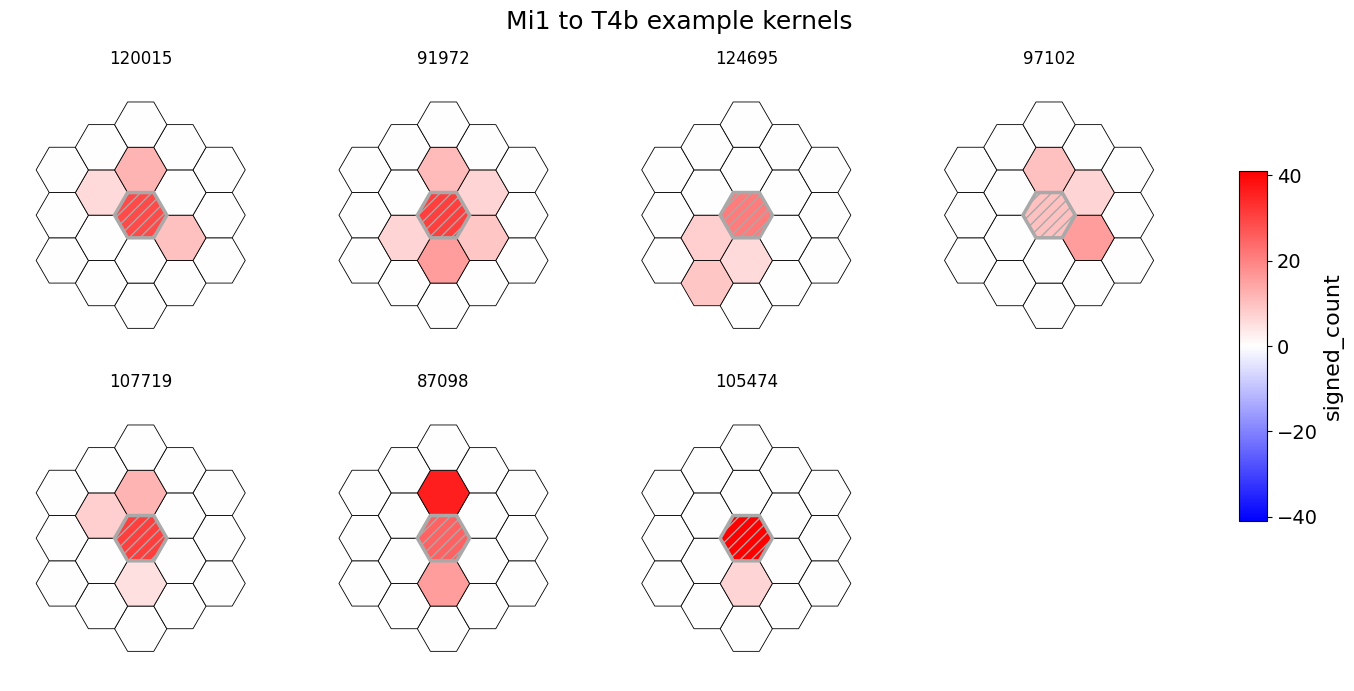

In [11]:
import math

n_samples = 7
max_cols = 4

valid_posts = (
    full_kernels
    .dropna(subset=["post", "target_p", "target_q"])
    [["post", "target_p", "target_q"]]
    .drop_duplicates()
)

n_samples = min(n_samples, len(valid_posts))

post_ids = (
    valid_posts["post"]
    .sample(n=n_samples, random_state=0)
    .to_list()
)

# only values from sampled cells
plot_df = full_kernels[full_kernels["post"].isin(post_ids)].copy()

vmax = np.abs(plot_df["signed_count"]).max()
shared_norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

n = len(post_ids)
ncols = min(max_cols, n)
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(3.5 * ncols, 3.5 * nrows),
    squeeze=False,
)

fig.suptitle(
    f"{plot_df['pre_cell_type'].iloc[0]} to "
    f"{plot_df['post_cell_type'].iloc[0]} example kernels",
    fontsize=18,
)

axes_flat = axes.ravel()
for ax, post_id in zip(axes_flat, post_ids):
    ax.axis("off")
    cell_df = plot_df[plot_df['post']==post_id]
    plot_spatial_kernel_hex(cell_df, value_col="signed_count", 
                        radius=4, cmap="bwr", 
                        norm = shared_norm, 
                        add_colorbar=False,
                        plot_labels=False, 
                        ax=ax,use_input_relative_to_target=True,
                        mirror_x=False,
                        mirror_y=False,
                        title=post_id)
for ax in axes_flat[n:]:
    ax.axis("off")
sm = plt.cm.ScalarMappable(norm=shared_norm, cmap=plt.get_cmap("bwr"))
sm.set_array([])

cax = fig.add_axes([0.9, 0.25, 0.02, 0.5]) # [left, bottom, width, height]
cbar = fig.colorbar(
    sm,
    cax=cax,
    shrink=0.4,
    location="right",
    label="Mean signed synapse count",
)
cbar.ax.tick_params(labelsize=14)
cbar.set_label("signed_count", fontsize=16)
plt.tight_layout(rect=[0, 0, 0.88, 1]) #[left, bottom, right, top]
# plt.tight_layout(rect=[0, 0, 0.92, 0.96])
plt.show()

<Axes: title={'center': 'mean_signed_count'}>

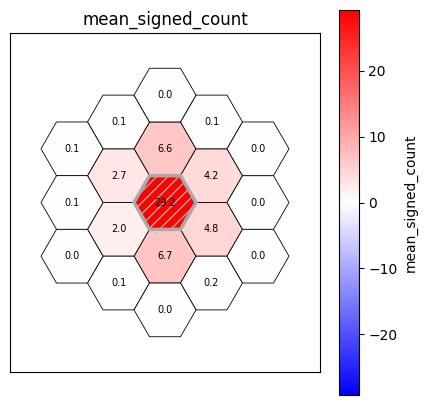

In [6]:
plot_spatial_kernel_hex(kernel, value_col="mean_signed_count", 
                        radius=4, 
                        add_colorbar=True, 
                        title=None)

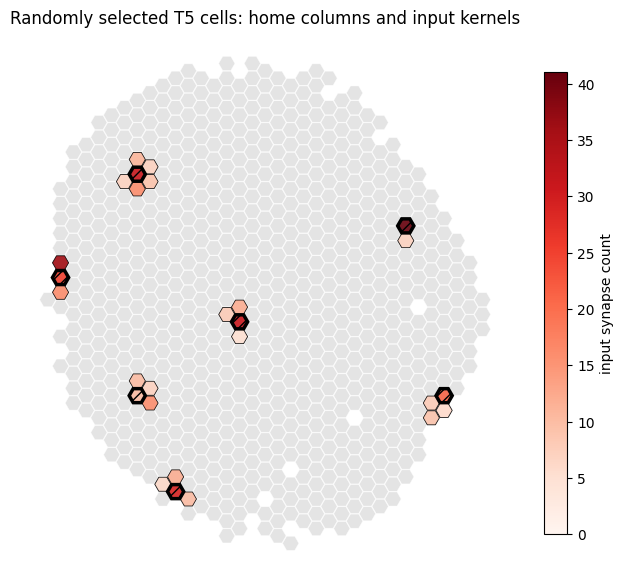

In [7]:
df = full_kernels.copy()


# Absolute presynaptic/input column coordinates
plot_df["input_p"] = plot_df["target_p"] - plot_df["dp"]
plot_df["input_q"] = plot_df["target_q"] - plot_df["dq"]

# Collapse in case multiple rows map to same input column for same post cell
plot_df = (
    plot_df
    .groupby(["post", "target_p", "target_q", "input_p", "input_q"], as_index=False)
    .agg(count=("count", "sum"))
)

# Background eye map: all T5 home columns in this full table
eye = (
    df[["target_p", "target_q"]]
    .dropna()
    .drop_duplicates()
    .rename(columns={"target_p": "p", "target_q": "q"})
)

x_eye, y_eye = pq_to_xy(
    eye["p"].to_numpy(),
    eye["q"].to_numpy(),
    hexsize=1.0,
    rotate=-np.pi / 6,
)

eye["x_plot"] = x_eye
eye["y_plot"] = y_eye

# Input columns for the selected cells
x_in, y_in = pq_to_xy(
    plot_df["input_p"].to_numpy(),
    plot_df["input_q"].to_numpy(),
    hexsize=1.0,
    rotate=-np.pi / 6,
)

plot_df["x_plot"] = x_in
plot_df["y_plot"] = y_in

# Home columns for the selected cells
homes = (
    plot_df[["post", "target_p", "target_q"]]
    .drop_duplicates()
    .rename(columns={"target_p": "p", "target_q": "q"})
)

x_home, y_home = pq_to_xy(
    homes["p"].to_numpy(),
    homes["q"].to_numpy(),
    hexsize=1.0,
    rotate=-np.pi / 6,
)

homes["x_plot"] = x_home
homes["y_plot"] = y_home

hexsize = 1.0
cmap = plt.get_cmap("Reds")
norm = mpl.colors.Normalize(
    vmin=0,
    vmax=plot_df["count"].max() if plot_df["count"].max() > 0 else 1,
)

# if plot_df['signed_count'].mean() < 0:
#     cmap = plt.get_cmap("Blues")
#     norm = mpl.colors.Normalize(
#     vmin=0,
#     vmax=plot_df["count"].max() if plot_df["count"].max() > 0 else 1,
# )


fig, ax = plt.subplots(figsize=(8, 8))

# 1. Plot all T5 columns as pale background
for _, row in eye.iterrows():
    ax.add_patch(
        RegularPolygon(
            (row["x_plot"], row["y_plot"]),
            numVertices=6,
            radius=hexsize * 0.95,
            orientation=np.pi / 6,
            facecolor="lightgray",
            edgecolor="white",
            linewidth=0.4,
            alpha=0.6,
        )
    )

# 2. Plot selected input columns colored by synapse count
# Draw only nonzero input bins if desired
nonzero_inputs = plot_df[plot_df["count"] > 0].copy()

for _, row in nonzero_inputs.iterrows():
    ax.add_patch(
        RegularPolygon(
            (row["x_plot"], row["y_plot"]),
            numVertices=6,
            radius=hexsize * 0.95,
            orientation=np.pi / 6,
            facecolor=cmap(norm(row["count"])),
            edgecolor="black",
            linewidth=0.6,
            alpha=0.9,
        )
    )

# 3. Highlight the three T5 home columns by darkening/outline
for _, row in homes.iterrows():
    ax.add_patch(
        RegularPolygon(
            (row["x_plot"], row["y_plot"]),
            numVertices=6,
            radius=hexsize * 0.95,
            orientation=np.pi / 6,
            facecolor="none",
            edgecolor="black",
            linewidth=2.5,
            hatch="///",
        )
    )

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
fig.colorbar(sm, ax=ax, shrink=0.75, label="input synapse count")

ax.set_aspect("equal")
ax.autoscale_view()
ax.axis("off")
ax.set_title("Randomly selected T5 cells: home columns and input kernels")

plt.show()

## Plot mean kernel

<Axes: title={'center': 'mean_signed_count'}>

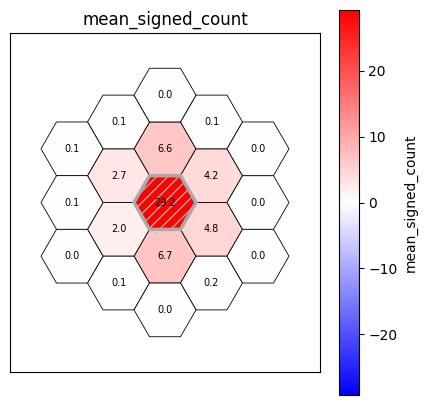

In [8]:

plot_spatial_kernel_hex(kernel, value_col="mean_signed_count", 
                        radius=4, 
                        add_colorbar=True, 
                        title=None)

In [9]:
post_type = "T4b"
post_type_inputs = df = edges.query(
        "post_cell_type == @post_type"
    ).copy()
input_types = post_type_inputs['pre_cell_type'].unique()

value_col = "mean_signed_count"
# post_type = "T4b"

kernels = {}

for pre_type in input_types:
    kernel, full = compute_kernel(
        edges,
        pre_type=pre_type,
        post_type=post_type,
        radius=3
    )
    kernels[pre_type] = kernel
    
threshold = 0.1

kernel_strength = {
    pre_type: kernels[pre_type][value_col].abs().max()
    for pre_type in input_types
}

input_types = [
    pre_type
    for pre_type in input_types
    if kernel_strength[pre_type] >= threshold
]

input_types = sorted(
    input_types,
    key=lambda pre_type: kernel_strength[pre_type],
    reverse=True
)

/tmp/ipykernel_60308/3393165534.py:72: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


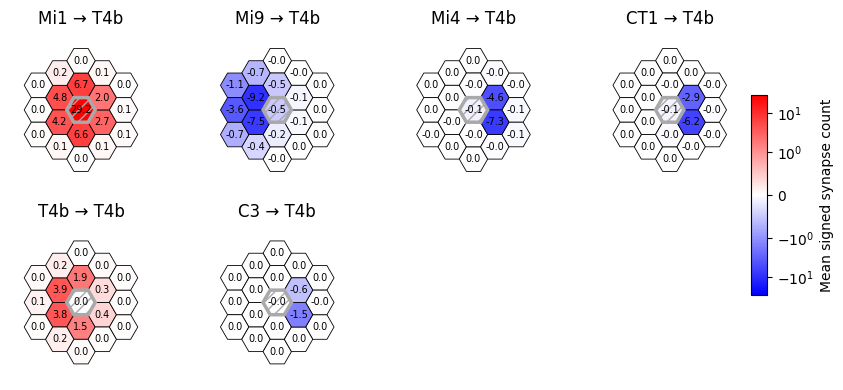

In [10]:

from matplotlib.colors import TwoSlopeNorm,  SymLogNorm
all_vals = np.concatenate([
    k[value_col].to_numpy()
    for k in kernels.values()
])

vmax = np.nanmax(np.abs(all_vals))

# norm = TwoSlopeNorm(
#     vmin=-vmax,
#     vcenter=0,
#     vmax=vmax
# )

norm = SymLogNorm(
    linthresh=1,      # values between -1 and 1 are linear
    linscale=1,
    vmin=-vmax,
    vmax=vmax,
    base=10
)

import math
n = len(input_types)
ncols = min(4, n)
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(2 * ncols, 2 * nrows),
    squeeze=False
)

axes_flat = axes.flatten()

for ax, pre_type in zip(axes_flat, input_types):
    plot_spatial_kernel_hex(
        kernels[pre_type],
        value_col=value_col,
        radius=2,
        cmap="bwr",
        norm=norm,
        ax=ax,
        title=f"{pre_type} → {post_type}",
        plot_labels=True, 
        use_input_relative_to_target=True,
        mirror_x=True,
        mirror_y=True,
    )


for ax in axes_flat:
    ax.axis("off")

# Common colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=plt.get_cmap("bwr"))
sm.set_array([])
plt.tight_layout(rect=[0, 0, 0.88, 1]) #[left, bottom, right, top]

cax = fig.add_axes([0.97, 0.25, 0.02, 0.5]) # [left, bottom, width, height]
cbar = fig.colorbar(
    sm,
    cax=cax,
    shrink=0.4,
    location="right",
    label="Mean signed synapse count"
)

# fig.suptitle(f"Signed spatial input kernels onto {post_type}", fontsize=16, y=1.02)

fig.tight_layout()
# fig.savefig(f"images/{post_type}_input_RF.png", dpi=300)
plt.show()